<div style=" background-color: RGB(0,114,200);" >
<h1 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">PROJET 10 DATA ANALYST</h1>
<h2 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">Scénario B, Le projet libre
</h2>
</div>

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Scraping</h2>
</div>

Dans ce projet, nous allons étudier un jeu de données textuel composé de textes poétiques en langue française.

La première étape va consister à scraper le site Poetica : https://www.poetica.fr/

Nous voulons récupérer un jeu de données contenant les informations suivantes : Auteur, Titre, Texte, Date. 

On va procéder en plusieurs étapes pour réaliser le scraper.

A la vue de la structure du site, on va commencer par réaliser un scraper qui récupère le lien menant à la production de chaque auteurs recensés.

In [5]:
# =========================
# SCRAPING POETICA – AUTEURS
# =========================

import time
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.chrome.service import Service as ChromeService
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC


chrome_driver_path = r"..."
chrome_binary_path = r"..."

base_url = "https://www.poetica.fr/"


def setup_driver():

    options = Options()
    options.add_argument("--headless=new")
    options.binary_location = chrome_binary_path

    service = ChromeService(executable_path=chrome_driver_path)

    return webdriver.Chrome(service=service, options=options)


def main():

    driver = setup_driver()
    wait = WebDriverWait(driver, 20)

    print("Chargement de la page...")
    driver.get(base_url)

    # attendre directement le conteneur des auteurs
    container = wait.until(
        EC.presence_of_element_located(
            (By.ID, "menu-poemes-par-auteur-container")
        )
    )

    print("Bloc auteurs trouvé")

    author_links = container.find_elements(By.TAG_NAME, "a")

    print(f"\n{len(author_links)} auteurs trouvés\n")

    for link in author_links:

        name = link.text.strip()
        url = link.get_attribute("href")

        if name:
            print(name)
            print(url)
            print("-" * 40)

    driver.quit()


if __name__ == "__main__":
    main()

Chargement de la page...
Bloc auteurs trouvé

118 auteurs trouvés

ACKERMANN Louise
https://www.poetica.fr/categories/louise-ackermann/
----------------------------------------
AGRIPPA D’AUBIGNÉ Théodore
https://www.poetica.fr/categories/theodore-agrippa-aubigne/
----------------------------------------
ALLAIS Alphonse
https://www.poetica.fr/categories/alphonse-allais/
----------------------------------------
APOLLINAIRE Guillaume
https://www.poetica.fr/categories/guillaume-apollinaire/
----------------------------------------
ARAGON Louis
https://www.poetica.fr/categories/louis-aragon/
----------------------------------------
ARTAUD Antonin
https://www.poetica.fr/categories/antonin-artaud/
----------------------------------------
ARVERS Félix
https://www.poetica.fr/categories/felix-arvers/
----------------------------------------
BANVILLE (de) Théodore
https://www.poetica.fr/categories/theodore-de-banville/
----------------------------------------
BAUDELAIRE Charles
https://www.poetic

In [ ]:
Depuis là on va faire un test pour voir si on arrive à récupérer les urls des poèmes à partir de celles des auteurs.

In [9]:
# =========================
# SCRAPING POETICA – AUTEURS + POEMES
# =========================

import time
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.chrome.service import Service as ChromeService
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC


chrome_driver_path = r"..."
chrome_binary_path = r"..."

base_url = "https://www.poetica.fr/"


def setup_driver():

    options = Options()
    options.add_argument("--headless=new")
    options.binary_location = chrome_binary_path

    service = ChromeService(executable_path=chrome_driver_path)

    return webdriver.Chrome(service=service, options=options)


def main():

    driver = setup_driver()
    wait = WebDriverWait(driver, 20)

    print("\nChargement page principale...")
    driver.get(base_url)

    container = wait.until(
        EC.presence_of_element_located(
            (By.ID, "menu-poemes-par-auteur-container")
        )
    )

    author_elements = container.find_elements(By.TAG_NAME, "a")

    # convertir en liste python classique
    authors = []

    for a in author_elements:

        name = a.text.strip()
        url = a.get_attribute("href")

        if name and url:
            authors.append((name, url))

    print(f"{len(authors)} auteurs trouvés\n")

    # tester sur 5 auteurs
    for i, (author_name, author_url) in enumerate(authors[:5]):

        print("\n==============================")
        print(f"Auteur {i+1} :", author_name)
        print(author_url)

        driver.get(author_url)

        time.sleep(2)

        poem_links = wait.until(
            EC.presence_of_all_elements_located(
                (By.XPATH, "//a[@rel='bookmark']")
            )
        )

        print(f"{len(poem_links)} poèmes trouvés\n")

        for poem in poem_links:

            title = poem.text.strip()
            url = poem.get_attribute("href")

            print("Poème :", title)
            print("URL   :", url)
            print("-" * 40)

    driver.quit()


if __name__ == "__main__":
    main()


Chargement page principale...
118 auteurs trouvés


Auteur 1 : ACKERMANN Louise
https://www.poetica.fr/categories/louise-ackermann/
47 poèmes trouvés

Poème : À Alfred de Musset
URL   : https://www.poetica.fr/poeme-726/louise-ackermann-a-alfred-de-musset/
----------------------------------------
Poème : À une artiste
URL   : https://www.poetica.fr/poeme-3961/louise-ackermann-a-une-artiste/
----------------------------------------
Poème : Adieu à la poésie
URL   : https://www.poetica.fr/poeme-453/louise-ackermann-adieu-a-la-poesie/
----------------------------------------
Poème : Aux femmes
URL   : https://www.poetica.fr/poeme-455/louise-ackermann-aux-femmes/
----------------------------------------
Poème : Bel astre voyageur
URL   : https://www.poetica.fr/poeme-524/louise-ackermann-bel-astre-voyageur/
----------------------------------------
Poème : Daphné
URL   : https://www.poetica.fr/poeme-3992/louise-ackermann-daphne/
----------------------------------------
Poème : De la Lumière 

Petit test pour voir si on récupère bien les textes sur un auteur

In [13]:
# =========================
# SCRAPING POETICA – TEXTE COMPLET
# =========================

import time
import re

from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.chrome.service import Service as ChromeService
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC


chrome_driver_path = r"..."
chrome_binary_path = r"..."

base_url = "https://www.poetica.fr/"


def setup_driver():

    options = Options()
    options.add_argument("--headless=new")
    options.binary_location = chrome_binary_path

    service = ChromeService(executable_path=chrome_driver_path)

    return webdriver.Chrome(service=service, options=options)


def extraire_date(reference):

    match = re.search(r"\b(1[6-9]\d{2}|20\d{2})\b", reference)

    if match:
        return match.group(0)

    return ""


def main():

    driver = setup_driver()
    wait = WebDriverWait(driver, 20)

    print("\nChargement page principale...")
    driver.get(base_url)

    container = wait.until(
        EC.presence_of_element_located(
            (By.ID, "menu-poemes-par-auteur-container")
        )
    )

    author_elements = container.find_elements(By.TAG_NAME, "a")

    authors = []

    for a in author_elements:

        name = a.text.strip()
        url = a.get_attribute("href")

        if name and url:
            authors.append((name, url))

    print(f"{len(authors)} auteurs trouvés\n")

    # seulement premier auteur pour test
    for author_name, author_url in authors[:1]:

        print("\n==============================")
        print("Auteur :", author_name)

        driver.get(author_url)

        time.sleep(2)

        poem_elements = wait.until(
            EC.presence_of_all_elements_located(
                (By.XPATH, "//a[@rel='bookmark']")
            )
        )

        # convertir en liste python
        poems = []

        for p in poem_elements:

            title = p.text.strip()
            url = p.get_attribute("href")

            if title and url:
                poems.append((title, url))

        print(f"{len(poems)} poèmes trouvés")

        poems_data = []

        # boucle niveau 3
        for title, url in poems:

            driver.get(url)

            time.sleep(2)

            paragraphs = wait.until(
                EC.presence_of_all_elements_located(
                    (By.XPATH, "//div[contains(@class,'entry-content')]//p")
                )
            )

            texte = []
            reference = ""

            for i, p in enumerate(paragraphs):

                content = p.text.strip()

                if i == len(paragraphs) - 1:

                    reference = content

                else:

                    texte.append(content)

            texte_final = "\n".join(texte)

            date = extraire_date(reference)

            data = {

                "Auteur": author_name,
                "Titre": title,
                "Texte": texte_final,
                "Date": date,
                "Reference": reference,
                "URL": url
            }

            poems_data.append(data)

            # print pour vérifier
            print("\n--------------------")
            print("Titre :", title)
            print("Date :", date)

            print("\nTexte (début):\n")
            print(texte_final[:400])

            print("\nRéférence :")
            print(reference)

            print("--------------------")

    driver.quit()


if __name__ == "__main__":
    main()


Chargement page principale...
118 auteurs trouvés


Auteur : ACKERMANN Louise
47 poèmes trouvés

--------------------
Titre : À Alfred de Musset
Date : 1871

Texte (début):

Un poète est parti ; sur sa tombe fermée
Pas un chant, pas un mot dans cette langue aimée
Dont la douceur divine ici-bas l’enivrait.
Seul, un pauvre arbre triste à la pâle verdure,
Le saule qu’il rêvait, au vent du soir, murmure
Sur son ombre éplorée un tendre et long regret.
Ce n’est pas de l’oubli ; nous répétons encore,
Poëte de l’amour, ces chants que fit éclore
Dans ton âme éperdue un éternel

Référence :
Louise Ackermann, Premières Poésies, 1871
--------------------

--------------------
Titre : À une artiste
Date : 1871

Texte (début):

Puisque les plus heureux ont des douleurs sans nombre,
Puisque le sol est froid, puisque les cieux sont lourds,
Puisque l’homme ici-bas promène son cœur sombre
Parmi les vains regrets et les courtes amours,
Que faire de la vie ? Ô notre âme immortelle,
Où jeter tes désirs et

In [ ]:
# =========================
# SCRAPING POETICA – DATASET COMPLET
# =========================

import time
import re
import json
import os

from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.chrome.service import Service as ChromeService
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC


chrome_driver_path = r"..."
chrome_binary_path = r"..."

base_url = "https://www.poetica.fr/"

output_file = r"..."

os.makedirs(r"...", exist_ok=True)


def setup_driver():

    options = Options()

    options.add_argument("--headless=new")
    options.add_argument("--disable-gpu")
    options.add_argument("--no-sandbox")

    options.binary_location = chrome_binary_path

    service = ChromeService(executable_path=chrome_driver_path)

    return webdriver.Chrome(service=service, options=options)


def extraire_date(reference):

    match = re.search(r"\b(1[6-9]\d{2}|20\d{2})\b", reference)

    if match:
        return match.group(0)

    return ""


def sauvegarde_progressive(data):

    with open(output_file, "w", encoding="utf-8") as f:

        json.dump(data, f, ensure_ascii=False, indent=2)


def main():

    driver = setup_driver()

    wait = WebDriverWait(driver, 20)

    print("\nChargement page principale...")
    driver.get(base_url)

    container = wait.until(

        EC.presence_of_element_located(

            (By.ID, "menu-poemes-par-auteur-container")

        )
    )

    author_elements = container.find_elements(By.TAG_NAME, "a")

    authors = []

    for a in author_elements:

        name = a.text.strip()

        url = a.get_attribute("href")

        if name and url:

            authors.append((name, url))

    print(f"{len(authors)} auteurs trouvés\n")

    dataset = []

    total_poems = 0


    for a_index, (author_name, author_url) in enumerate(authors):

        print("\n==============================")
        print(f"Auteur {a_index+1}/{len(authors)}")
        print(author_name)

        driver.get(author_url)

        time.sleep(2)

        poem_elements = wait.until(

            EC.presence_of_all_elements_located(

                (By.XPATH, "//a[@rel='bookmark']")

            )
        )

        poems = []

        for p in poem_elements:

            title = p.text.strip()

            url = p.get_attribute("href")

            if title and url:

                poems.append((title, url))

        print(f"{len(poems)} poèmes trouvés")

        for p_index, (title, url) in enumerate(poems):

            try:

                driver.get(url)

                time.sleep(2)

                paragraphs = wait.until(

                    EC.presence_of_all_elements_located(

                        (By.XPATH, "//div[contains(@class,'entry-content')]//p")

                    )
                )

                texte = []

                reference = ""

                for i, p in enumerate(paragraphs):

                    content = p.text.strip()

                    if i == len(paragraphs) - 1:

                        reference = content

                    else:

                        texte.append(content)

                texte_final = "\n".join(texte)

                date = extraire_date(reference)

                data = {

                    "Auteur": author_name,

                    "Titre": title,

                    "Texte": texte_final,

                    "Date": date,

                    "Reference": reference,

                    "URL": url

                }

                dataset.append(data)

                total_poems += 1

                print(f"{total_poems} | {author_name} | {title}")

                # sauvegarde tous les 20 poèmes
                if total_poems % 20 == 0:

                    sauvegarde_progressive(dataset)

            except Exception as e:

                print("Erreur :", title)

                print(e)


    driver.quit()

    # sauvegarde finale
    sauvegarde_progressive(dataset)

    print("\n==============================")
    print("SCRAPING TERMINÉ")
    print(f"{total_poems} poèmes sauvegardés")
    print("Fichier :", os.path.abspath(output_file))


if __name__ == "__main__":

    main()

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Traitement de données</h2>
</div>

Le scraping étant terminé, on va devoir transformé la donnée pour la manipuler plus facilement. 

In [339]:
import json

file_path = r"..."

with open(file_path, "r", encoding="utf-8") as f:
    data=json.load(f)

count_poem = 0 
for poem in data:
    count_poem += 1

print(f"Il y a {count_poem} poèmes dans le jeu de données")

Il y a 3180 poèmes dans le jeu de données


In [341]:
file_path = r"..."

with open(file_path, "r", encoding ="utf-8") as f:
     data=json.load(f)

for poem in data:
    texte = poem["Texte"]
    n_mots = len(texte.split())
    poem["Nombre_de_mots"] = n_mots
    
# sauvegarder
with open(file_path, "w", encoding="utf-8") as f:
    json.dump(data, f, ensure_ascii=False, indent=2)

print("Ajout terminé ✅")

Ajout terminé ✅


In [343]:
import pandas as pd

with open(file_path, "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data)

print(df.head(2))

             Auteur               Titre  \
0  ACKERMANN Louise  À Alfred de Musset   
1  ACKERMANN Louise       À une artiste   

                                               Texte  Date  \
0  Un poète est parti ; sur sa tombe fermée\nPas ...  1871   
1  Puisque les plus heureux ont des douleurs sans...  1871   

                                   Reference  \
0  Louise Ackermann, Premières Poésies, 1871   
1  Louise Ackermann, Premières poésies, 1871   

                                                 URL  Nombre_de_mots  
0  https://www.poetica.fr/poeme-726/louise-ackerm...             403  
1  https://www.poetica.fr/poeme-3961/louise-acker...             206  


La première chose que je veux étudier c'est le nombre de mots.

Je vais en effet l'exploiter pour réaliser une série temporelle.

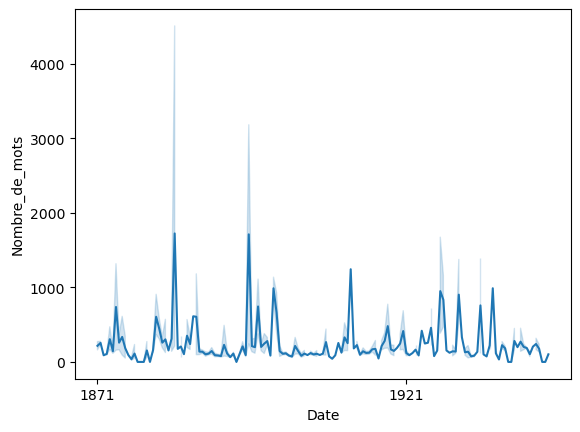

In [346]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import seaborn as sns

ax = sns.lineplot(
    data=df,
    x="Date",
    y="Nombre_de_mots",
    estimator="mean"
)

ax.xaxis.set_major_locator(MultipleLocator(100))

plt.show()

Bon, déjà là il semblerait qu'il me manque une partie des dates, certains auteurs sont antérieurs à 1871

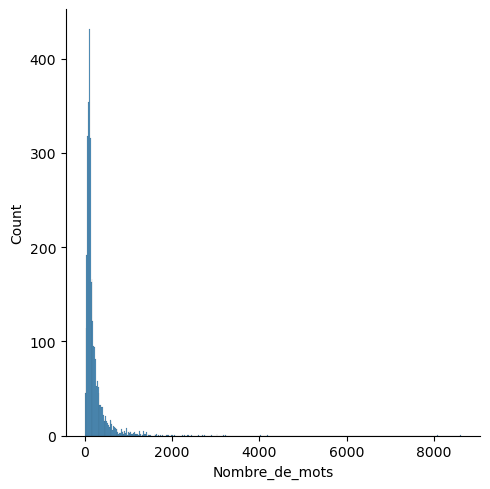

In [348]:
sns.displot(df, x="Nombre_de_mots")

Là on voit que les valeurs extrêmes vont influencer la moyenne si c'est cet indicateur qu'on utilise. 

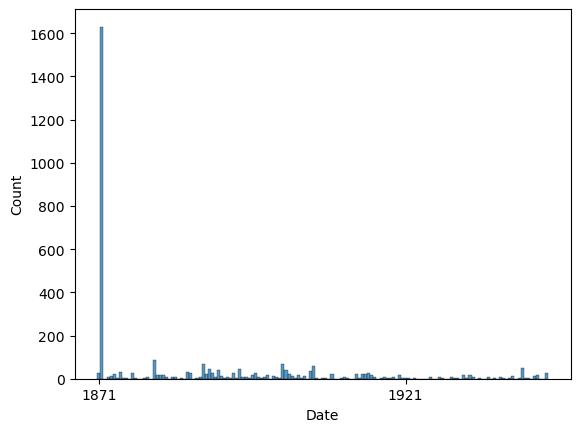

In [350]:

ax = sns.histplot(
    data=df,
    x="Date"
)

ax.xaxis.set_major_locator(MultipleLocator(100))

plt.show()

Là il semblerait que j'ai + de 1600 poèmes qui datent de 1872, ce qui est très bizarre. On va regarder les données

In [352]:
Nb_poem_date = df.groupby("Date").count().reset_index()
Nb_poem_date.head(5)

,Date,Auteur,Titre,Texte,Reference,URL,Nombre_de_mots
0,,1630,1630,1630,1630,1630,1630
1,1668,2,2,2,2,2,2
2,1669,1,1,1,1,1,1
3,1678,1,1,1,1,1,1
4,1679,1,1,1,1,1,1


Ok donc sur 3180 poèmes, j'en ai 1630 sans date donc en gros 50%

In [354]:
df_date = df[df["Date"] != ""].copy()

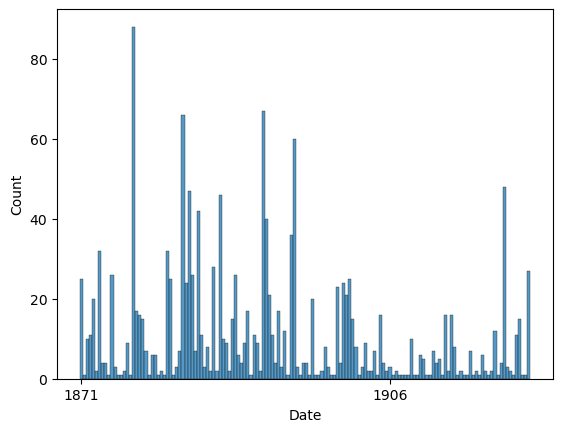

In [355]:
ax = sns.histplot(df_date, x="Date")

ax.xaxis.set_major_locator(MultipleLocator(100))

plt.show()

La disposition des dates existantes semblent déjà beaucoup moins problématique

In [358]:
df_date["Date"] = pd.to_numeric(df_date["Date"], errors="coerce")

In [359]:
len(df_date)

1550

<Axes: xlabel='Date', ylabel='Count'>

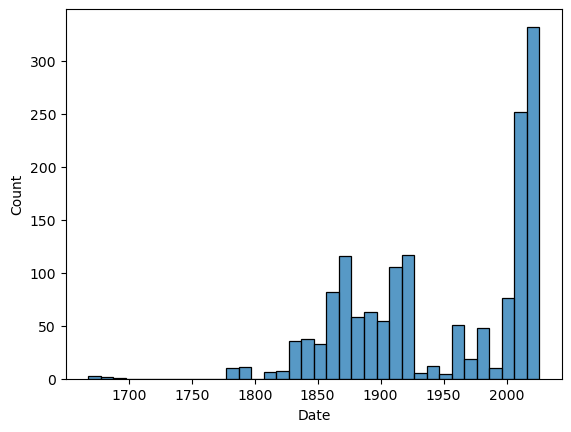

In [367]:
sns.histplot(df_date, x="Date", binwidth=10)

C'est là qu'on réalise que les poèmes non datés, ne sont pas les plus récents, ce qui déséquilibre de df

Donc on va opter pour une strat de remplissage

Première question : Y a t-il des auteurs sans dates ?

Si oui... Il va falloir bricoler. 

Si non, on peut utiliser les dates existantes pour simuler le reste en créant une gaussienne personnalisée pour chaque auteur en fonction des dates existantes. 

In [373]:
df["Date"] = pd.to_numeric(df["Date"], errors="coerce")

In [375]:
df_auteur = df.groupby("Auteur", dropna=False)["Date"].mean().reset_index()

In [377]:
df_auteur.head()

,Auteur,Date
0,ACKERMANN Louise,1872.200000
1,AGRIPPA D’AUBIGNÉ Théodore,1874.000000
2,ALLAIS Alphonse,1854.000000
3,APOLLINAIRE Guillaume,1912.375000
4,ARAGON Louis,1947.428571


In [379]:
df_auteur_sans_date = df_auteur[df_auteur["Date"].isna()].copy()

In [381]:
df_auteur_sans_date.head(2)

,Auteur,Date
9,BEAUCHEMIN Nérée,NaN
10,BELLAY (du) Joachim,NaN


In [383]:
len(df_auteur_sans_date)

16

Ok, donc 16 auteurs sans dates.

Pour le moment on va travailler sur les autres. 

In [387]:
df_X = df[df["Auteur"] == "ACKERMANN Louise"]

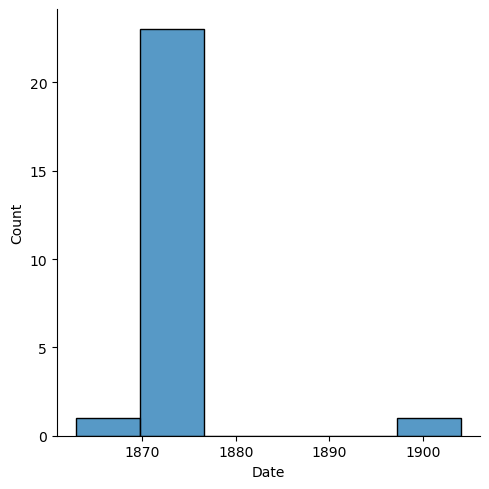

In [389]:
sns.displot(df_X, x="Date")

Maintenant, on veut aussi voir le nombre d'auteurs qui ont au moins 1 poème daté et 1 poème non daté.

In [392]:
df.head()

,Auteur,Titre,Texte,Date,Reference,URL,Nombre_de_mots
0,ACKERMANN Louise,À Alfred de Musset,Un poète est parti ; sur sa tombe fermée\nPas ...,1871.0,"Louise Ackermann, Premières Poésies, 1871",https://www.poetica.fr/poeme-726/louise-ackerm...,403
1,ACKERMANN Louise,À une artiste,Puisque les plus heureux ont des douleurs sans...,1871.0,"Louise Ackermann, Premières poésies, 1871",https://www.poetica.fr/poeme-3961/louise-acker...,206
2,ACKERMANN Louise,Adieu à la poésie,"Mes pleurs sont à moi, nul au monde\nNe les a ...",1871.0,"Louise Ackermann, Premières poésies (1871)",https://www.poetica.fr/poeme-453/louise-ackerm...,73
3,ACKERMANN Louise,Aux femmes,"S’il arrivait un jour, en quelque lieu sur ter...",NaN,,https://www.poetica.fr/poeme-455/louise-ackerm...,253
4,ACKERMANN Louise,Bel astre voyageur,"À La Comète de 1861\nBel astre voyageur, hôte ...",NaN,"Louise Ackermann, Poésies Philosophiques",https://www.poetica.fr/poeme-524/louise-ackerm...,143


In [394]:
poete_at_least_one_dated_undated = []

for auteur, group in df.groupby("Auteur"):

    date = group["Date"].notna().any()
    pas_date = group["Date"].isna().any()

    if date and pas_date:
        poete_at_least_one_dated_undated.append(auteur)

print(poete_at_least_one_dated_undated)

['ACKERMANN Louise', 'AGRIPPA D’AUBIGNÉ Théodore', 'ALLAIS Alphonse', 'APOLLINAIRE Guillaume', 'ARAGON Louis', 'ARTAUD Antonin', 'ARVERS Félix', 'BANVILLE (de) Théodore', 'BAUDELAIRE Charles', 'BEN SLIMA Nadia', 'BENISTANT Adrien', 'BENJELLOUN Rhita', 'BOILEAU Nicolas', 'BREGAINT Christophe', 'BRETON Jules', 'CALLIS-SABOT Isabelle', 'CENDRARS Blaise', 'CHALINE Thomas', 'CHATEAUBRIAND (de) François-René', 'CHEDID Andrée', 'CHENIER André', 'COPPÉE François', 'CORBIÈRE Tristan', 'CROS Charles', 'DAVIN Sandrine', 'DELAVIGNE Casimir', 'DELMONT Benjamin', 'DESBORDES-VALMORE Marceline', 'DESROSIERS Susy', 'DORGE Jean-Charles', 'DOUGLAS Chloe', 'DUFRENOY Adélaïde', 'ELUARD Paul', 'FABIÉ François', 'FAYARD Luc', 'FOUREST Georges', 'GAUTIER Théophile', 'HUGO Victor', 'JARRY Alfred', 'KRYSINSKA Marie', 'LA FONTAINE (de) Jean', 'LACAUSSADE Auguste', 'LAFORGUE Jules', 'LAMARTINE (de) Alphonse', 'LARRIEU Christine', 'LERMAN ENRIQUEZ Alix', 'LERUTAN Isaac', 'LUEZIOR Claude', 'MALLARMÉ Stéphane', 'MAT

In [396]:
print(len(poete_at_least_one_dated_undated))

86


Pour tous ceux là on va faire une KDE et redistribuer les non datés aléatoirement en fonction de la KDE

In [399]:
import numpy as np
from scipy.stats import gaussian_kde

# copie des dates
df["Date_imputee"] = df["Date"]

for auteur in poete_at_least_one_dated_undated:

    mask_auteur = df["Auteur"] == auteur
    df_auteur = df.loc[mask_auteur]

    # dates connues
    dates_connues = df_auteur.loc[
        df_auteur["Date"].notna(), "Date"
    ].astype(float).values

    if len(dates_connues) == 0:
        continue

    # index des dates manquantes
    index_missing = df_auteur.loc[
        df_auteur["Date"].isna()
    ].index

    # bornes (sécurité)
    min_date = int(np.min(dates_connues))
    max_date = int(np.max(dates_connues))

    # cas 1 : toutes les dates identiques (variance = 0)
    if np.std(dates_connues) < 1e-8:

        for idx in index_missing:
            df.loc[idx, "Date_imputee"] = int(dates_connues[0])

        continue

    # cas 2 : KDE possible
    try:
        kde = gaussian_kde(dates_connues)

        for idx in index_missing:

            date_sample = kde.resample(1)[0][0]
            date_sample = int(round(date_sample))

            # on borne pour éviter les aberrations
            date_sample = np.clip(date_sample, min_date, max_date)

            df.loc[idx, "Date_imputee"] = date_sample

    except Exception as e:
        # fallback : tirage empirique
        for idx in index_missing:
            df.loc[idx, "Date_imputee"] = int(np.random.choice(dates_connues))

print("Imputation terminée ✅")

Imputation terminée ✅


Un petit check pour vérifier : 

In [401]:
df_X = df[df["Auteur"] == "ACKERMANN Louise"]

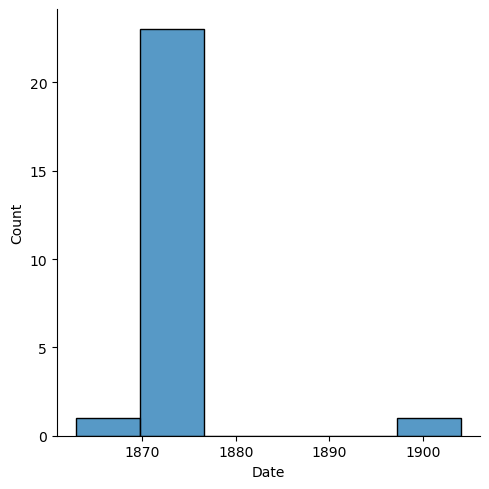

In [402]:
sns.displot(df_X, x="Date")

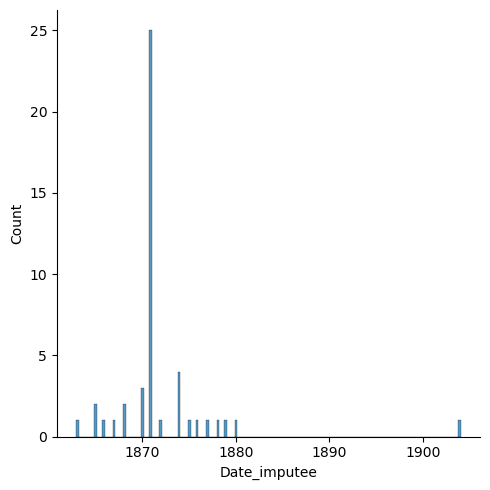

In [406]:
sns.displot(df_X, x="Date_imputee")

<Axes: xlabel='Date', ylabel='Count'>

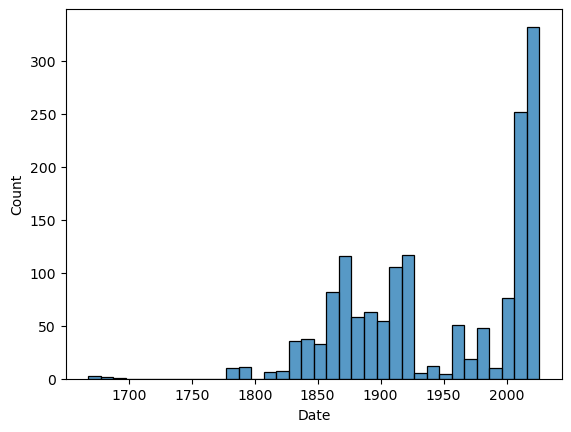

In [407]:
sns.histplot(df_date, x="Date", binwidth=10)

<Axes: xlabel='Date_imputee', ylabel='Count'>

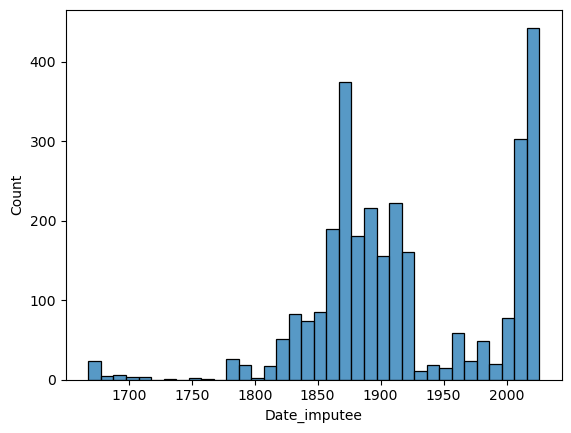

In [408]:
sns.histplot(df, x="Date_imputee", binwidth=10)

Du coup il me reste la liste des 16 auteurs sans date aucune

Pour le moment on va les sortir

In [414]:
df = df[df["Date_imputee"] != ""]

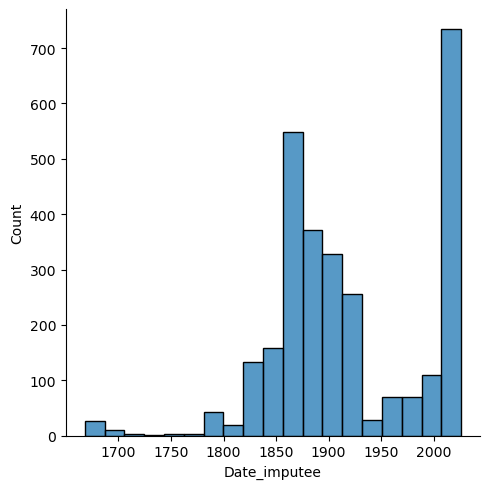

In [416]:
sns.displot(df, x="Date_imputee")

<Axes: xlabel='Date_imputee', ylabel='Nombre_de_mots'>

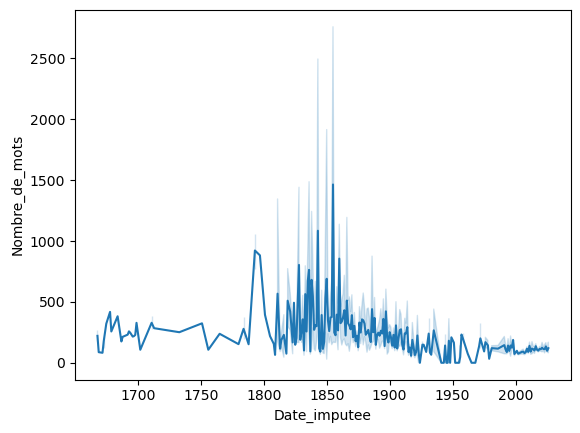

In [418]:
sns.lineplot(df, x="Date_imputee", y="Nombre_de_mots", estimator="mean")

Et voilà, on a notre série temporelle

Ok, maintenant on va s'intéresser à la diversité lexicale avec les stop words

In [421]:
from spacy.lang.fr.stop_words import STOP_WORDS

In [422]:
print(STOP_WORDS)

{'puisque', 'ceux-ci', 'dit', 'mais', 'ton', 'où', 'desquelles', 'telle', 'pouvait', 'ceci', 'ayant', 'autrui', 'toi', 'encore', 'surtout', 'quelques', 'facon', 'ès', 'troisièmement', 'près', 'desquels', 'va', 'peu', 'assez', 'concernant', 'tous', 'houp', 'juste', 'duquel', 'déja', 'neanmoins', 'quant', 'dits', 'quinze', 'douzième', 'miennes', 'ou', 'reste', 'j’', 'certaines', 'peut', 'depuis', 'jusque', 'première', 'elle-meme', 'devra', 'précisement', 'si', 'directe', 'tout', 'compris', 'quatrième', 'allaient', 'spécifiques', 'relative', 'avons', 'deux', 'hi', 'cinquantaine', 'onzième', 'parle', 'differente', 'lorsque', 'celui-ci', 'ceux', 'sienne', 'dire', 'deuxième', 'suivant', 'dedans', 'â', 'tels', 'anterieures', 'à', 'soi', 'moins', 'vas', 'semblaient', 'precisement', 'dix-huit', 'préalable', 'lès', 'jusqu', 'touchant', 'pourrais', 'avec', 'ouste', 'suffit', 'alors', 'vous-mêmes', 'cinquième', 'partant', 'a', 'revoici', 'da', 'as', 'seules', 'nombreux', 'sans', 'durant', 'ce', 'c

Je ne suis pas satisfait par la liste de spacy

On va faire une liste de stop_words personnalisé adaptée à objectif

On va prendre seulement déterminant, préposition et conjonction, ensuite on va lemmatiser :

In [429]:
determinants = {
    "le", "la", "les", "l'", 
    "un", "une", "des",
    "du", "de la", "de l'",
    "mon", "ma", "mes", "ton", "ta", "tes",
    "son", "sa", "ses",
    "notre", "nos",
    "votre", "vos",
    "leur", "leurs",
    "ce", "cet", "cette", "ces",
    "aucun", "aucune",
    "chaque",
    "certain", "certaine", "certains", "certaines",
    "tout", "tous", "toutes",
    "un", "une",
    "à",
    # contractés
    "au", "aux"
}
len(determinants)

42

In [431]:
prepositions = {
    "à", "de", "par", "pour", "en", "vers",
    "avec", "sans", "sous", "sur", "chez",
    "entre", "dans", "contre", "depuis",
    "pendant", "durant", "avant", "après",
    "vers", "envers", "malgré", "selon",
    "jusque", "jusqu'à"
}
len(prepositions)

24

In [433]:
conjunctions = {
    "et", "ou", "mais", "donc", "or", "ni", "car", 
    "que", "qu'",
    "si",
    "comme",
    "lorsque", "quand",
    "puisque",
    "quoique",
    "afin", "afin que",
    "parce que"
}
len(conjunctions)

18

In [435]:
stopwords_basic = determinants | prepositions | conjunctions

In [437]:
print(stopwords_basic)

{'puisque', 'cette', 'un', 'et', 'ma', 'ta', 'afin', 'de la', 'mais', 'ton', "de l'", 'lorsque', 'quand', 'leurs', 'pendant', 'au', 'que', "qu'", 'aux', 'nos', 'les', 'le', 'ses', 'la', 'sous', 'chez', 'des', 'votre', 'aucune', 'avant', 'parce que', 'par', 'cet', 'malgré', 'notre', 'à', 'quoique', 'son', 'dans', 'car', 'contre', 'tous', 'ni', 'aucun', 'avec', 'leur', 'vers', 'ou', 'or', "l'", 'mes', 'certain', 'toutes', 'envers', 'certaines', 'sans', 'sur', 'selon', 'durant', 'ce', 'certains', 'certaine', 'depuis', 'jusque', 'en', 'afin que', 'après', 'du', 'entre', 'si', 'tout', 'mon', "jusqu'à", 'vos', 'sa', 'une', 'pour', 'chaque', 'donc', 'tes', 'ces', 'comme', 'de'}


In [439]:
len(stopwords_basic)

83

Ok on va d'abord faire la lemmatisation :

In [442]:
import spacy

nlp = spacy.load("fr_core_news_sm")

df["tokens_lemmas"] = None

for index, row in df.iterrows():
    
    texte = row["Texte"]  # texte brut
    
    doc = nlp(texte)
    
    lemmas = [
        token.lemma_.lower()
        for token in doc
        if token.is_alpha
    ]
    
    df.at[index, "tokens_lemmas"] = lemmas

In [443]:
df.head(1)

,Auteur,Titre,Texte,Date,Reference,URL,Nombre_de_mots,Date_imputee,tokens_lemmas
0,ACKERMANN Louise,À Alfred de Musset,Un poète est parti ; sur sa tombe fermée\nPas ...,1871.0,"Louise Ackermann, Premières Poésies, 1871",https://www.poetica.fr/poeme-726/louise-ackerm...,403,1871.0,"[un, poète, être, parti, sur, son, tombe, ferm..."


In [444]:
df["tokens_clean"] = None
df["Nb_Token_lemmas"] = 0

In [445]:
list_stopwords = set(stopwords_basic) 

for index, row in df.iterrows():
    
    list_token = row["tokens_lemmas"].copy()  
    
    new_tokens = []
    
    for token in list_token:
        if token not in list_stopwords:
            new_tokens.append(token)
    
    df.at[index, "tokens_clean"] = new_tokens
    df.at[index, "Nb_Token_lemmas"] = len(set(new_tokens))
     


   

In [446]:
df.head()

,Auteur,Titre,Texte,Date,Reference,URL,Nombre_de_mots,Date_imputee,tokens_lemmas,tokens_clean,Nb_Token_lemmas
0,ACKERMANN Louise,À Alfred de Musset,Un poète est parti ; sur sa tombe fermée\nPas ...,1871.0,"Louise Ackermann, Premières Poésies, 1871",https://www.poetica.fr/poeme-726/louise-ackerm...,403,1871.0,"[un, poète, être, parti, sur, son, tombe, ferm...","[poète, être, parti, tombe, fermé, pas, chant,...",196
1,ACKERMANN Louise,À une artiste,Puisque les plus heureux ont des douleurs sans...,1871.0,"Louise Ackermann, Premières poésies, 1871",https://www.poetica.fr/poeme-3961/louise-acker...,206,1871.0,"[puisque, le, plus, heureux, avoir, un, douleu...","[plus, heureux, avoir, douleur, nombre, sol, ê...",102
2,ACKERMANN Louise,Adieu à la poésie,"Mes pleurs sont à moi, nul au monde\nNe les a ...",1871.0,"Louise Ackermann, Premières poésies (1871)",https://www.poetica.fr/poeme-453/louise-ackerm...,73,1871.0,"[mon, pleur, être, à, moi, nul, au, monde, ne,...","[pleur, être, moi, nul, monde, ne, avoir, comp...",41
3,ACKERMANN Louise,Aux femmes,"S’il arrivait un jour, en quelque lieu sur ter...",NaN,,https://www.poetica.fr/poeme-455/louise-ackerm...,253,1865.0,"[il, arriver, un, jour, en, quelque, lieu, sur...","[il, arriver, jour, quelque, lieu, terre, entr...",89
4,ACKERMANN Louise,Bel astre voyageur,"À La Comète de 1861\nBel astre voyageur, hôte ...",NaN,"Louise Ackermann, Poésies Philosophiques",https://www.poetica.fr/poeme-524/louise-ackerm...,143,1875.0,"[à, le, comète, de, bel, astre, voyageur, hôte...","[comète, bel, astre, voyageur, hôte, qui, nous...",78


<Axes: xlabel='Nombre_de_mots', ylabel='Nb_Token_lemmas'>

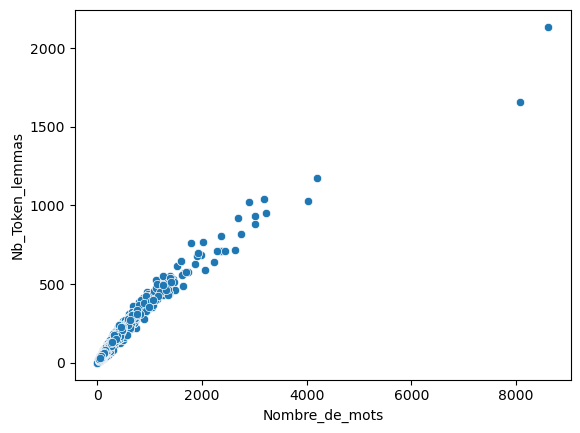

In [447]:
sns.scatterplot(df, x="Nombre_de_mots", y="Nb_Token_lemmas")

C'est magnifique

Je suis tombé par hasard sur une loi fondamentale du language, la loi de Herdan/Heaps : https://en.wikipedia.org/wiki/Heaps%27s_law

In [451]:
df = df.sort_values("Date", ascending=False)
df.head(10)

,Auteur,Titre,Texte,Date,Reference,URL,Nombre_de_mots,Date_imputee,tokens_lemmas,tokens_clean,Nb_Token_lemmas
1606,LERMAN ENRIQUEZ Alix,Folie,Je prie comme une orante pour que reviennent l...,2026.0,"Alix Lerman Enriquez, 2026",https://www.poetica.fr/poeme-9237/alix-lerman-...,123,2026.0,"[je, prier, comme, un, orant, pour, que, reven...","[je, prier, orant, revenir, oiseau, je, crier,...",63
2934,VILLEBRAMAR Jean-Pierre,Lettre à des amis défunts,"à Michelle, leur sœur…\nJ’aime la nuit, ses om...",2026.0,"Villebramar, mai 2026",https://www.poetica.fr/poeme-9338/villebramar-...,148,2026.0,"[à, michelle, son, sœur, aimer, le, nuit, son,...","[michelle, sœur, aimer, nuit, ombre, tutélaire...",74
3140,ZERDOUMI Kamal,Elle et lui,Lui se demande s’il est encore temps\nelle ray...,2026.0,"Kamal Zerdoumi, 2026",https://www.poetica.fr/poeme-8989/kamal-zerdou...,61,2026.0,"[lui, se, demande, il, être, encore, temps, lu...","[lui, se, demande, il, être, encore, temps, lu...",36
3169,ZERDOUMI Kamal,Inhumains,Le sang du silence ne cesse de couler\nde tout...,2026.0,"Kamal Zerdoumi, 2026",https://www.poetica.fr/poeme-8987/kamal-zerdou...,70,2026.0,"[le, sang, de, silence, ne, cesser, de, couler...","[sang, silence, ne, cesser, couler, bouche, ba...",41
2062,RANOUX Maëlle,Je suis une femme libre,Je suis\nUne femme\nLibre.\nLibre de penser\nL...,2026.0,"Maëlle Ranoux, 2026",https://www.poetica.fr/poeme-9330/maelle-ranou...,368,2026.0,"[je, être, un, femme, libre, libre, de, penser...","[je, être, femme, libre, libre, penser, libre,...",157
2895,VILLEBRAMAR Jean-Pierre,Exils,"Tu ne le savais pas,\nla vie, là-bas te serait...",2026.0,"Villebramar, 2026",https://www.poetica.fr/poeme-8997/villebramar-...,155,2026.0,"[tu, ne, le, savai, pas, le, vie, là, bas, te,...","[tu, ne, savai, pas, vie, là, bas, te, être, d...",62
3118,ZERDOUMI Kamal,Clémence,Patte de velours du Soir\nLe soleil intact tar...,2026.0,"Kamal Zerdoumi, 2026",https://www.poetica.fr/poeme-8985/kamal-zerdou...,71,2026.0,"[patte, de, velours, de, soir, le, soleil, int...","[patte, velours, soir, soleil, intact, tard, s...",45
2602,URBAN-MENNINGER Françoise,L’arrivée de la neige,\nl’arrivée de la neige\nannonce-t-elle la bla...,2025.0,"Françoise Urban-Menninger, 2025",https://www.poetica.fr/poeme-8951/francoise-ur...,49,2025.0,"[arrivée, de, le, neige, annonce, le, blancheu...","[arrivée, neige, annonce, blancheur, âme, erra...",29
2877,VILLEBRAMAR Jean-Pierre,Catharsis,"Tu es partie.\nRien n’a changé, tout change et...",2025.0,"Villebramar, 2025",https://www.poetica.fr/poeme-8936/villebramar-...,77,2025.0,"[tu, être, partie, rien, avoir, changer, tout,...","[tu, être, partie, rien, avoir, changer, chang...",40
2610,URBAN-MENNINGER Françoise,Une rose rouge carmin,une rose rouge carmin\nourle son cœur odorant\...,2025.0,"Françoise Urban-Menninger, 2025",https://www.poetica.fr/poeme-8703/francoise-ur...,38,2025.0,"[un, rose, rouge, carmin, ourle, son, cœur, od...","[rose, rouge, carmin, ourle, cœur, odorer, je,...",23


In [452]:
import os

os.chdir(r"C:\Users\victo\OneDrive\Bureau\OCP10")

Periods = pd.read_excel("Périodes.xlsx")

Periods.head(2)

,Date_imputee,Période
0,1660,Classicisme
1,1661,Classicisme


In [453]:
df = df.merge(Periods, how="inner", on="Date_imputee")
df.head()

,Auteur,Titre,Texte,Date,Reference,URL,Nombre_de_mots,Date_imputee,tokens_lemmas,tokens_clean,Nb_Token_lemmas,Période
0,LERMAN ENRIQUEZ Alix,Folie,Je prie comme une orante pour que reviennent l...,2026.0,"Alix Lerman Enriquez, 2026",https://www.poetica.fr/poeme-9237/alix-lerman-...,123,2026.0,"[je, prier, comme, un, orant, pour, que, reven...","[je, prier, orant, revenir, oiseau, je, crier,...",63,Contemporain
1,VILLEBRAMAR Jean-Pierre,Lettre à des amis défunts,"à Michelle, leur sœur…\nJ’aime la nuit, ses om...",2026.0,"Villebramar, mai 2026",https://www.poetica.fr/poeme-9338/villebramar-...,148,2026.0,"[à, michelle, son, sœur, aimer, le, nuit, son,...","[michelle, sœur, aimer, nuit, ombre, tutélaire...",74,Contemporain
2,ZERDOUMI Kamal,Elle et lui,Lui se demande s’il est encore temps\nelle ray...,2026.0,"Kamal Zerdoumi, 2026",https://www.poetica.fr/poeme-8989/kamal-zerdou...,61,2026.0,"[lui, se, demande, il, être, encore, temps, lu...","[lui, se, demande, il, être, encore, temps, lu...",36,Contemporain
3,ZERDOUMI Kamal,Inhumains,Le sang du silence ne cesse de couler\nde tout...,2026.0,"Kamal Zerdoumi, 2026",https://www.poetica.fr/poeme-8987/kamal-zerdou...,70,2026.0,"[le, sang, de, silence, ne, cesser, de, couler...","[sang, silence, ne, cesser, couler, bouche, ba...",41,Contemporain
4,RANOUX Maëlle,Je suis une femme libre,Je suis\nUne femme\nLibre.\nLibre de penser\nL...,2026.0,"Maëlle Ranoux, 2026",https://www.poetica.fr/poeme-9330/maelle-ranou...,368,2026.0,"[je, être, un, femme, libre, libre, de, penser...","[je, être, femme, libre, libre, penser, libre,...",157,Contemporain


Déjà dans un premier temps, on va voir le nombre de poèmes par périodes :

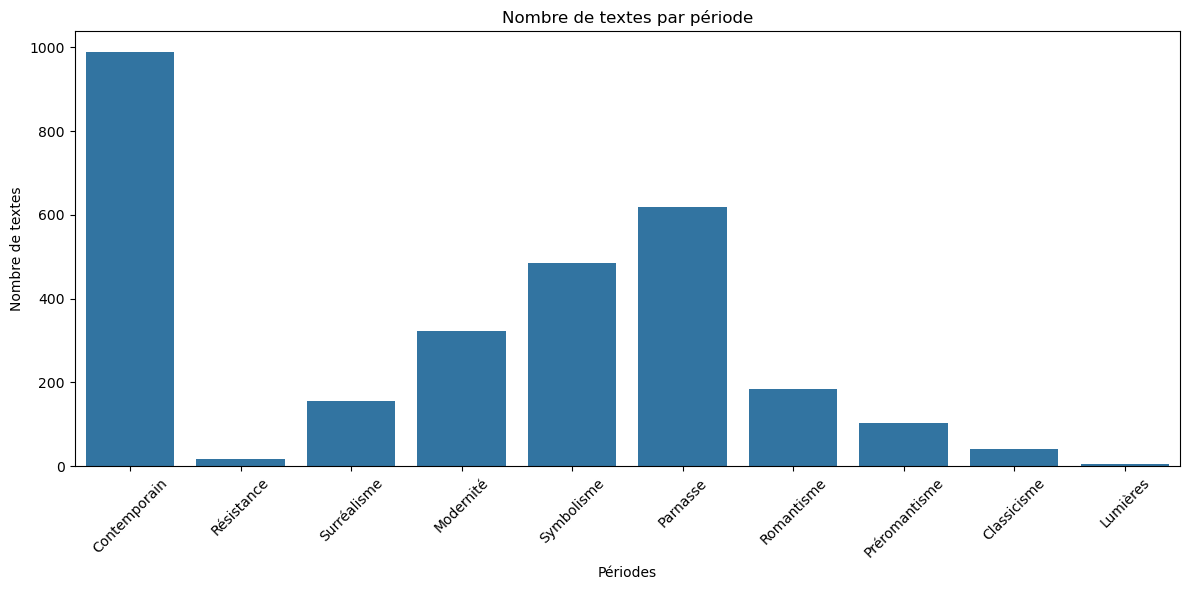

In [455]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

sns.countplot(
    data=df,
    x="Période"
)

plt.xlabel("Périodes")
plt.ylabel("Nombre de textes")
plt.title("Nombre de textes par période")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Répartition très inégalitaire

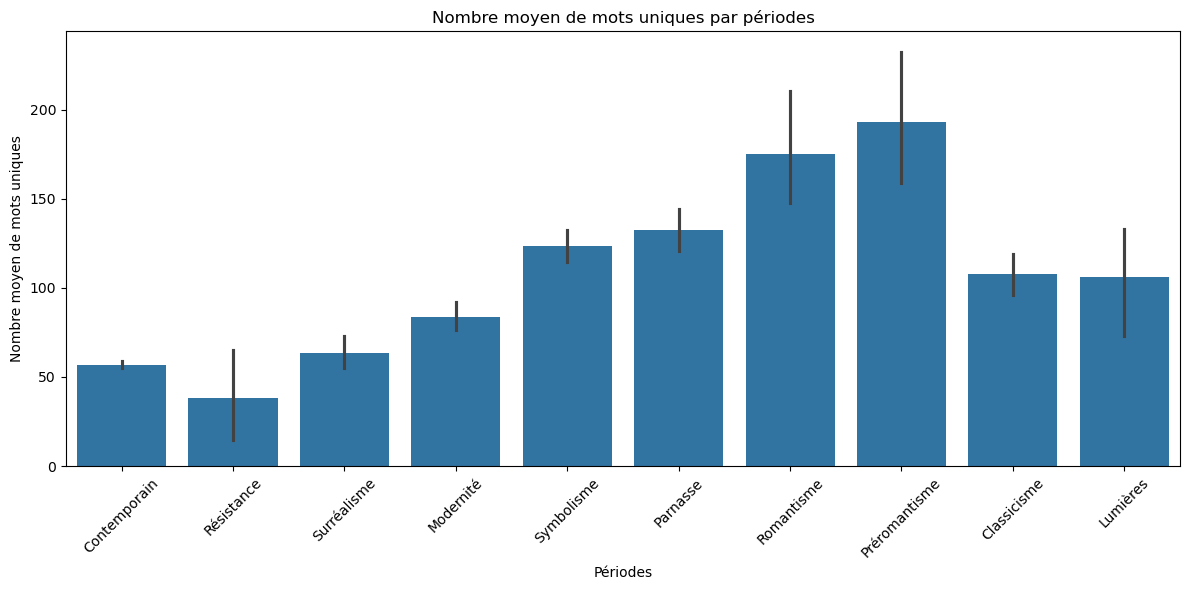

In [457]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

sns.barplot(
    data=df,
    x="Période",
    y="Nb_Token_lemmas",
    estimator="mean"
)

plt.xlabel("Périodes")
plt.ylabel("Nombre moyen de mots uniques")
plt.title("Nombre moyen de mots uniques par périodes")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

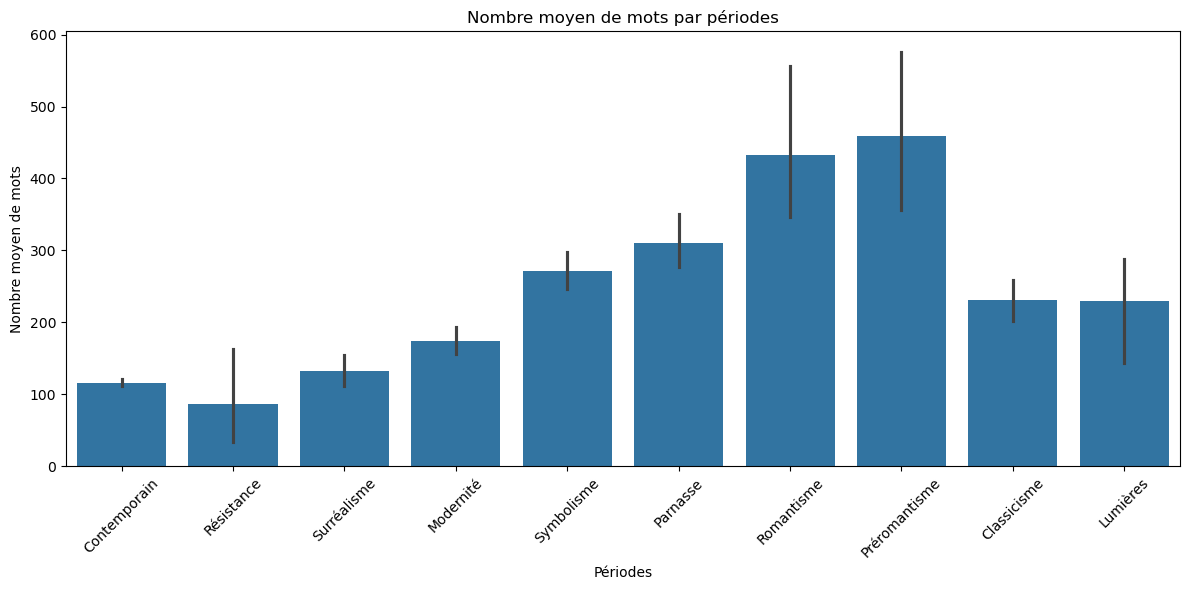

In [458]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

sns.barplot(
    data=df,
    x="Période",
    y="Nombre_de_mots",
    estimator="mean"
)

plt.xlabel("Périodes")
plt.ylabel("Nombre moyen de mots")
plt.title("Nombre moyen de mots par périodes")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Ok donc là on a deux mesures qui sont strictement corrélées à la longueure moyenne des poèmes par périodes. 

Ce qui serait peut être intéressant serait d'avoir le nombre de mots uniques réels par périodes. 

In [461]:
df_periodes = (
    df.groupby("Période")
    .agg(
        Mots_uniques=("tokens_clean", lambda x: list(set(sum(x, [])))),
        nb_poemes=("tokens_clean", "size")
    )
    .reset_index()
)

In [462]:
df_periodes.head(10)

,Période,Mots_uniques,nb_poemes
0,Classicisme,"[causer, aide, fête, cognée, louis, aimez, gag...",40
1,Contemporain,"[traiter, lanterne, imager, flamber, aimez, mu...",989
2,Lumières,"[aide, traiter, vieux, fois, accourcir, enfuit...",4
3,Modernité,"[lanterne, flamber, aimez, musique, rapière, s...",322
4,Parnasse,"[traiter, altérer, conspire, lanterne, flamber...",619
5,Préromantisme,"[traiter, altérer, conspire, suprême, toile, b...",102
6,Romantisme,"[éman, traiter, altérer, entrecoupé, rêveurs, ...",184
7,Résistance,"[traiter, legros, vieux, mémoire, fête, précéd...",18
8,Surréalisme,"[azaler, couvercle, prend, fête, lanterne, sen...",155
9,Symbolisme,"[éman, traiter, altérer, lanterne, blocus, rêv...",484


In [463]:
df_periodes["Nb_mots_uniques"] = df_periodes["Mots_uniques"].apply(len)

In [464]:
df_periodes.head(10)

,Période,Mots_uniques,nb_poemes,Nb_mots_uniques
0,Classicisme,"[causer, aide, fête, cognée, louis, aimez, gag...",40,1960
1,Contemporain,"[traiter, lanterne, imager, flamber, aimez, mu...",989,11049
2,Lumières,"[aide, traiter, vieux, fois, accourcir, enfuit...",4,357
3,Modernité,"[lanterne, flamber, aimez, musique, rapière, s...",322,7192
4,Parnasse,"[traiter, altérer, conspire, lanterne, flamber...",619,13192
5,Préromantisme,"[traiter, altérer, conspire, suprême, toile, b...",102,5481
6,Romantisme,"[éman, traiter, altérer, entrecoupé, rêveurs, ...",184,7469
7,Résistance,"[traiter, legros, vieux, mémoire, fête, précéd...",18,496
8,Surréalisme,"[azaler, couvercle, prend, fête, lanterne, sen...",155,3512
9,Symbolisme,"[éman, traiter, altérer, lanterne, blocus, rêv...",484,10950


In [465]:
df_periodes["Mots_uniques_pondere"] = df_periodes["Nb_mots_uniques"] / df_periodes["nb_poemes"]
df_periodes.head(10)

,Période,Mots_uniques,nb_poemes,Nb_mots_uniques,Mots_uniques_pondere
0,Classicisme,"[causer, aide, fête, cognée, louis, aimez, gag...",40,1960,49.000000
1,Contemporain,"[traiter, lanterne, imager, flamber, aimez, mu...",989,11049,11.171891
2,Lumières,"[aide, traiter, vieux, fois, accourcir, enfuit...",4,357,89.250000
3,Modernité,"[lanterne, flamber, aimez, musique, rapière, s...",322,7192,22.335404
4,Parnasse,"[traiter, altérer, conspire, lanterne, flamber...",619,13192,21.311793
5,Préromantisme,"[traiter, altérer, conspire, suprême, toile, b...",102,5481,53.735294
6,Romantisme,"[éman, traiter, altérer, entrecoupé, rêveurs, ...",184,7469,40.592391
7,Résistance,"[traiter, legros, vieux, mémoire, fête, précéd...",18,496,27.555556
8,Surréalisme,"[azaler, couvercle, prend, fête, lanterne, sen...",155,3512,22.658065
9,Symbolisme,"[éman, traiter, altérer, lanterne, blocus, rêv...",484,10950,22.623967


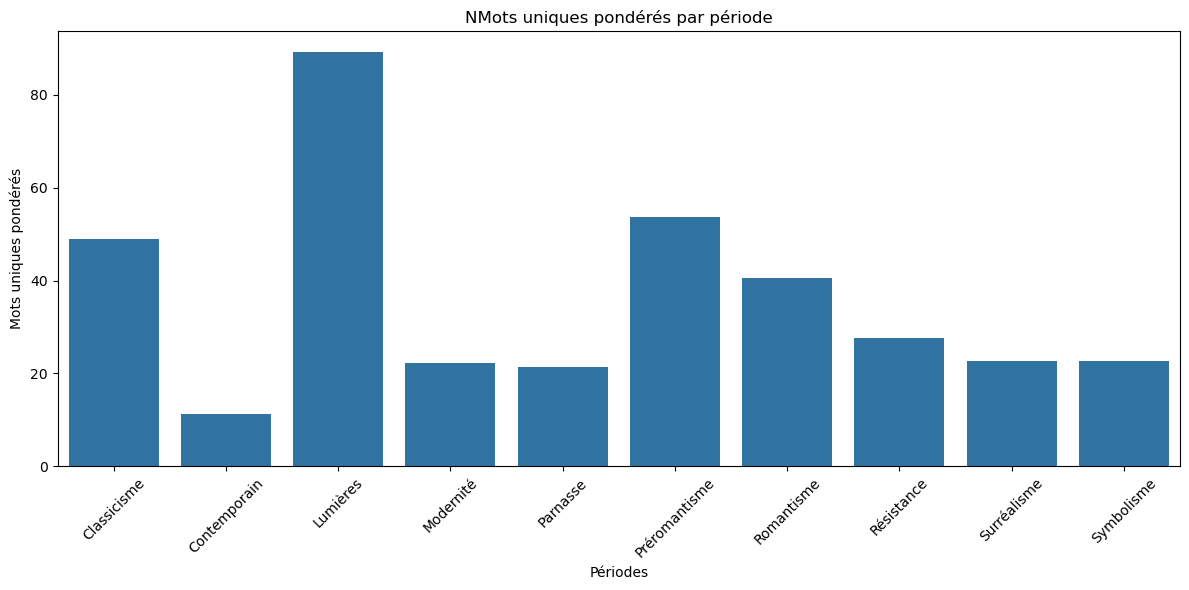

In [466]:
plt.figure(figsize=(12,6))

sns. barplot(
    data=df_periodes,
    x="Période",
    y="Mots_uniques_pondere"
)

plt.xlabel("Périodes")
plt.ylabel("Mots uniques pondérés")
plt.title("Nb Mots uniques pondérés par période")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Mesure trop dépendante à la taille des corpus par période. 

Inintéressant...

On va maintenant regarder les mots spécifiques

In [469]:
mots_specifiques = []

for index, row in df_periodes.iterrows():

    periode = row["Période"]
    mots_periode = set(row["Mots_uniques"])

    # Tous les mots des autres périodes
    autres_mots = set()

    for i, other_row in df_periodes.iterrows():

        if i != index:
            autres_mots.update(other_row["Mots_uniques"])

    # Mots uniquement présents dans cette période
    mots_uniques_periode = list(mots_periode - autres_mots)

    mots_specifiques.append(mots_uniques_periode)
    

In [470]:
df_periodes["Mots_specifiques"] = mots_specifiques

df_periodes["Nb_mots_specifiques"] = (
    df_periodes["Mots_specifiques"]
    .apply(len)
)

In [471]:
df_periodes.head(10)


,Période,Mots_uniques,nb_poemes,Nb_mots_uniques,Mots_uniques_pondere,Mots_specifiques,Nb_mots_specifiques
0,Classicisme,"[causer, aide, fête, cognée, louis, aimez, gag...",40,1960,49.000000,"[amalthée, sauverai, nitée, ellébore, hollande...",206
1,Contemporain,"[traiter, lanterne, imager, flamber, aimez, mu...",989,11049,11.171891,"[voc, maillage, tricheur, aimeraient, rajeunis...",3619
2,Lumières,"[aide, traiter, vieux, fois, accourcir, enfuit...",4,357,89.250000,"[gloutonnement, enseignent, ôton, impossibilit...",24
3,Modernité,"[lanterne, flamber, aimez, musique, rapière, s...",322,7192,22.335404,"[déplore, godet, pâteux, larysacanthu, défiant...",1418
4,Parnasse,"[traiter, altérer, conspire, lanterne, flamber...",619,13192,21.311793,"[élytre, méritoire, aussitost, dévier, cliner,...",3585
5,Préromantisme,"[traiter, altérer, conspire, suprême, toile, b...",102,5481,53.735294,"[demandoier, changeon, retraça, traités, myrto...",796
6,Romantisme,"[éman, traiter, altérer, entrecoupé, rêveurs, ...",184,7469,40.592391,"[crurent, glorifie, clytemnestre, érèbe, kiou,...",1131
7,Résistance,"[traiter, legros, vieux, mémoire, fête, précéd...",18,496,27.555556,"[botté, admettr, legros, mâcher, supportai, lu...",13
8,Surréalisme,"[azaler, couvercle, prend, fête, lanterne, sen...",155,3512,22.658065,"[azaler, denrer, luisante, ricaneur, seguin, t...",319
9,Symbolisme,"[éman, traiter, altérer, lanterne, blocus, rêv...",484,10950,22.623967,"[conformer, blocus, acclam, cerrito, gouverna,...",2367


In [472]:
print(
    df_periodes.loc[
        df_periodes["Période"] == "Contemporain",
        "Mots_specifiques"
    ].values[0]
)

['voc', 'maillage', 'tricheur', 'aimeraient', 'rajeunis', 'imager', 'ressasse', 'gibran', 'fontainebleau', 'semtex', 'démocratie', 'aragon', 'calfeutrée', 'persécution', 'encercle', 'bonz', 'miami', 'buenos', 'soulagent', 'atôme', 'femmer', 'porteras', 'dodelinent', 'susurre', 'bifurcation', 'valparaiso', 'popocatepelt', 'kamoulcke', 'accessoirement', 'algorithme', 'imparfaitemer', 'anobli', 'franchie', 'asphyxié', 'ocreuse', 'dordogne', 'bué', 'tagueule', 'interrogaient', 'pardonnerai', 'intemporelle', 'gontaut', 'déambuler', 'doucir', 'zombie', 'culto', 'hétérodoxe', 'réécrire', 'fabriquent', 'diapason', 'opalescent', 'nylon', 'plèvre', 'quiero', 'dialecte', 'instantanément', 'mortifier', 'portera', 'déchiquetée', 'chardonneret', 'mécréant', 'fe', 'chrysalide', 'mainter', 'incarnée', 'accoler', 'échapée', 'incorrigible', 'déambulant', 'liquéfier', 'baratin', 'détergent', 'sirocco', 'alleluia', 'relents', 'méfie', 'chersonisso', 'défais', 'bistrot', 'rocker', 'miraflore', 'foncé', 'ca

Bon en fait une partie de ces résultats est influencée par la taille des corpus par période qui est très hétérogène.

Par exemple, pour les mots uniques pondérés, la période contemporaine est celle qui à la plus faible valeur, mais d'un autre côté c'est aussi la période dont le nombre de poèmes domine le corpus.

Donc suivant la loi de Head c'est parfaitement logique.

Malheureusement résultat pas très intéressant.

Maintenant on va faire le stacked barplot :

In [478]:
df.head()

,Auteur,Titre,Texte,Date,Reference,URL,Nombre_de_mots,Date_imputee,tokens_lemmas,tokens_clean,Nb_Token_lemmas,Période
0,LERMAN ENRIQUEZ Alix,Folie,Je prie comme une orante pour que reviennent l...,2026.0,"Alix Lerman Enriquez, 2026",https://www.poetica.fr/poeme-9237/alix-lerman-...,123,2026.0,"[je, prier, comme, un, orant, pour, que, reven...","[je, prier, orant, revenir, oiseau, je, crier,...",63,Contemporain
1,VILLEBRAMAR Jean-Pierre,Lettre à des amis défunts,"à Michelle, leur sœur…\nJ’aime la nuit, ses om...",2026.0,"Villebramar, mai 2026",https://www.poetica.fr/poeme-9338/villebramar-...,148,2026.0,"[à, michelle, son, sœur, aimer, le, nuit, son,...","[michelle, sœur, aimer, nuit, ombre, tutélaire...",74,Contemporain
2,ZERDOUMI Kamal,Elle et lui,Lui se demande s’il est encore temps\nelle ray...,2026.0,"Kamal Zerdoumi, 2026",https://www.poetica.fr/poeme-8989/kamal-zerdou...,61,2026.0,"[lui, se, demande, il, être, encore, temps, lu...","[lui, se, demande, il, être, encore, temps, lu...",36,Contemporain
3,ZERDOUMI Kamal,Inhumains,Le sang du silence ne cesse de couler\nde tout...,2026.0,"Kamal Zerdoumi, 2026",https://www.poetica.fr/poeme-8987/kamal-zerdou...,70,2026.0,"[le, sang, de, silence, ne, cesser, de, couler...","[sang, silence, ne, cesser, couler, bouche, ba...",41,Contemporain
4,RANOUX Maëlle,Je suis une femme libre,Je suis\nUne femme\nLibre.\nLibre de penser\nL...,2026.0,"Maëlle Ranoux, 2026",https://www.poetica.fr/poeme-9330/maelle-ranou...,368,2026.0,"[je, être, un, femme, libre, libre, de, penser...","[je, être, femme, libre, libre, penser, libre,...",157,Contemporain


In [479]:
import numpy as np

df["Texte"] = df["Texte"].replace(r"^\s*$", np.nan, regex=True)
df = df.dropna(subset=["Texte"])

In [480]:
from collections import Counter

all_pos = []

for tokens in df["tokens_clean"]:

    doc = nlp(" ".join(tokens))

    counter = Counter(
        token.pos_
        for token in doc
    )

    all_pos.append(counter)

df["pos_counts"] = all_pos

In [481]:
df.head()

,Auteur,Titre,Texte,Date,Reference,URL,Nombre_de_mots,Date_imputee,tokens_lemmas,tokens_clean,Nb_Token_lemmas,Période,pos_counts
0,LERMAN ENRIQUEZ Alix,Folie,Je prie comme une orante pour que reviennent l...,2026.0,"Alix Lerman Enriquez, 2026",https://www.poetica.fr/poeme-9237/alix-lerman-...,123,2026.0,"[je, prier, comme, un, orant, pour, que, reven...","[je, prier, orant, revenir, oiseau, je, crier,...",63,Contemporain,"{'PRON': 9, 'ADJ': 21, 'VERB': 19, 'NOUN': 17,..."
1,VILLEBRAMAR Jean-Pierre,Lettre à des amis défunts,"à Michelle, leur sœur…\nJ’aime la nuit, ses om...",2026.0,"Villebramar, mai 2026",https://www.poetica.fr/poeme-9338/villebramar-...,148,2026.0,"[à, michelle, son, sœur, aimer, le, nuit, son,...","[michelle, sœur, aimer, nuit, ombre, tutélaire...",74,Contemporain,"{'ADJ': 17, 'VERB': 26, 'NOUN': 23, 'PRON': 16..."
2,ZERDOUMI Kamal,Elle et lui,Lui se demande s’il est encore temps\nelle ray...,2026.0,"Kamal Zerdoumi, 2026",https://www.poetica.fr/poeme-8989/kamal-zerdou...,61,2026.0,"[lui, se, demande, il, être, encore, temps, lu...","[lui, se, demande, il, être, encore, temps, lu...",36,Contemporain,"{'PRON': 12, 'VERB': 11, 'AUX': 2, 'ADV': 3, '..."
3,ZERDOUMI Kamal,Inhumains,Le sang du silence ne cesse de couler\nde tout...,2026.0,"Kamal Zerdoumi, 2026",https://www.poetica.fr/poeme-8987/kamal-zerdou...,70,2026.0,"[le, sang, de, silence, ne, cesser, de, couler...","[sang, silence, ne, cesser, couler, bouche, ba...",41,Contemporain,"{'NOUN': 12, 'ADJ': 7, 'ADV': 8, 'VERB': 11, '..."
4,RANOUX Maëlle,Je suis une femme libre,Je suis\nUne femme\nLibre.\nLibre de penser\nL...,2026.0,"Maëlle Ranoux, 2026",https://www.poetica.fr/poeme-9330/maelle-ranou...,368,2026.0,"[je, être, un, femme, libre, libre, de, penser...","[je, être, femme, libre, libre, penser, libre,...",157,Contemporain,"{'PRON': 34, 'AUX': 19, 'NOUN': 52, 'ADJ': 54,..."


In [482]:
df["pos_counts"] = df["tokens_clean"].apply(
    lambda tokens: Counter(
        token.pos_
        for token in nlp(" ".join(tokens))
    )
)

In [483]:
df.head(2)

,Auteur,Titre,Texte,Date,Reference,URL,Nombre_de_mots,Date_imputee,tokens_lemmas,tokens_clean,Nb_Token_lemmas,Période,pos_counts
0,LERMAN ENRIQUEZ Alix,Folie,Je prie comme une orante pour que reviennent l...,2026.0,"Alix Lerman Enriquez, 2026",https://www.poetica.fr/poeme-9237/alix-lerman-...,123,2026.0,"[je, prier, comme, un, orant, pour, que, reven...","[je, prier, orant, revenir, oiseau, je, crier,...",63,Contemporain,"{'PRON': 9, 'ADJ': 21, 'VERB': 19, 'NOUN': 17,..."
1,VILLEBRAMAR Jean-Pierre,Lettre à des amis défunts,"à Michelle, leur sœur…\nJ’aime la nuit, ses om...",2026.0,"Villebramar, mai 2026",https://www.poetica.fr/poeme-9338/villebramar-...,148,2026.0,"[à, michelle, son, sœur, aimer, le, nuit, son,...","[michelle, sœur, aimer, nuit, ombre, tutélaire...",74,Contemporain,"{'ADJ': 17, 'VERB': 26, 'NOUN': 23, 'PRON': 16..."


In [484]:
periode_counts = {}

for periode, groupe in df.groupby("Période"):

    total = Counter()

    for counter in groupe["pos_counts"]:
        total.update(counter)

    periode_counts[periode] = total

In [485]:
df_pos = pd.DataFrame(periode_counts).T.fillna(0)

In [486]:
df_pos = df_pos.div(df_pos.sum(axis=1), axis=0)

In [487]:
df_pos = df_pos.div(df_pos.sum(axis=1), axis=0)

In [488]:
df_pos.head()

,ADP,NOUN,AUX,ADJ,VERB,PRON,ADV,DET,NUM,PROPN,X,CCONJ,SCONJ,INTJ,PUNCT,SYM
Classicisme,0.010392,0.200511,0.067802,0.156048,0.289267,0.122658,0.112436,0.011414,0.008688,0.017036,0.002215,0.001193,0.000341,0.000000,0.000000,0.000000
Contemporain,0.010862,0.221799,0.059712,0.184243,0.272649,0.119991,0.096390,0.009754,0.004904,0.016049,0.002053,0.000757,0.000730,0.000068,0.000041,0.000000
Lumières,0.008591,0.178694,0.065292,0.163230,0.309278,0.106529,0.118557,0.012027,0.018900,0.017182,0.000000,0.001718,0.000000,0.000000,0.000000,0.000000
Modernité,0.014250,0.223633,0.052944,0.201132,0.265566,0.114422,0.085753,0.013546,0.005689,0.018080,0.003154,0.001098,0.000648,0.000084,0.000000,0.000000
Parnasse,0.012014,0.214610,0.057937,0.190374,0.276747,0.113930,0.092493,0.011815,0.006302,0.019462,0.002325,0.001229,0.000457,0.000291,0.000008,0.000008


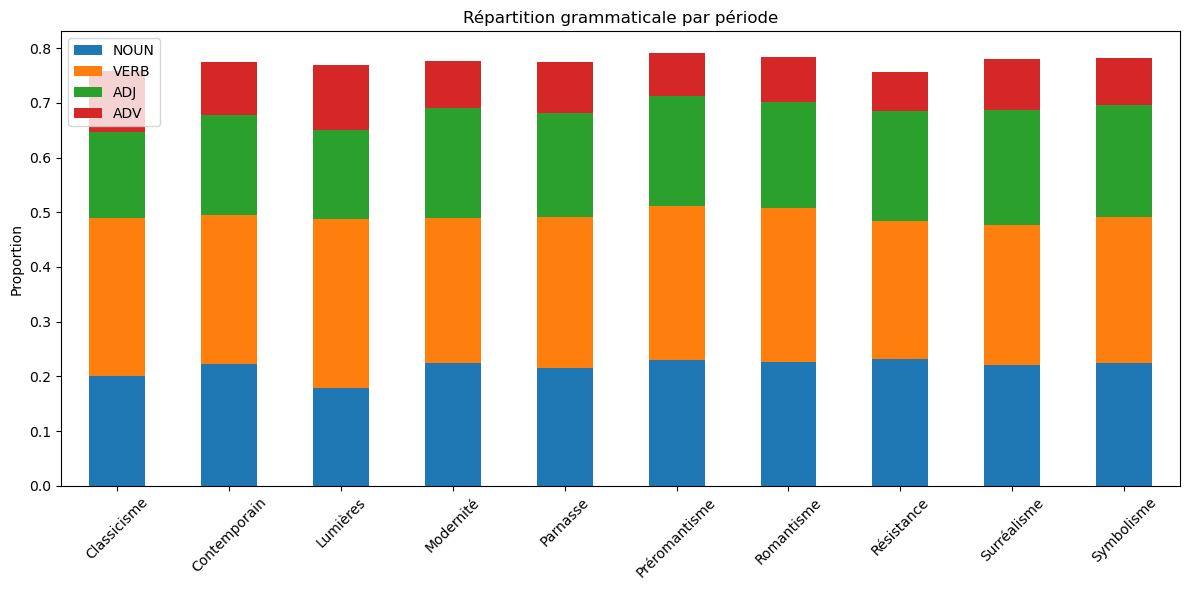

In [489]:
df_pos[["NOUN", "VERB", "ADJ", "ADV"]].plot(
    kind="bar",
    stacked=True,
    figsize=(12,6)
)

plt.ylabel("Proportion")
plt.title("Répartition grammaticale par période")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Bon bah en fait j'ai plus qu'à créer une colonne pour chaque type de mots

In [491]:
df_pos = df["pos_counts"].apply(pd.Series).fillna(0)

In [492]:
pos_cols = ["NOUN", "VERB", "ADJ", "ADV", "PRON"]

for col in pos_cols:

    df_pos[f"{col}_ratio"] = (
        df_pos[col] / df["Nb_Token_lemmas"]
    )

In [493]:
df_pos.head(1)

,PRON,ADJ,VERB,NOUN,ADP,ADV,AUX,PROPN,DET,NUM,...,SCONJ,CCONJ,INTJ,PUNCT,SYM,NOUN_ratio,VERB_ratio,ADJ_ratio,ADV_ratio,PRON_ratio
0,9.0,21.0,19.0,17.0,1.0,6.0,3.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.269841,0.301587,0.333333,0.095238,0.142857


In [541]:
df.head(1)

,Auteur,Titre,Texte,Date,Reference,URL,Nombre_de_mots,Date_imputee,tokens_lemmas,tokens_clean,Nb_Token_lemmas,Période,pos_counts
0,LERMAN ENRIQUEZ Alix,Folie,Je prie comme une orante pour que reviennent l...,2026.0,"Alix Lerman Enriquez, 2026",https://www.poetica.fr/poeme-9237/alix-lerman-...,123,2026.0,"[je, prier, comme, un, orant, pour, que, reven...","[je, prier, orant, revenir, oiseau, je, crier,...",63,Contemporain,"{'PRON': 9, 'ADJ': 21, 'VERB': 19, 'NOUN': 17,..."


In [543]:
df_final.head(1)

,Auteur,Titre,Texte,Date,Reference,URL,Nombre_de_mots,Date_imputee,tokens_lemmas,tokens_clean,Nb_Token_lemmas,pos_counts
0,LERMAN ENRIQUEZ Alix,Folie,Je prie comme une orante pour que reviennent l...,2026.0,"Alix Lerman Enriquez, 2026",https://www.poetica.fr/poeme-9237/alix-lerman-...,123,2026.0,"[je, prier, comme, un, orant, pour, que, reven...","[je, prier, orant, revenir, oiseau, je, crier,...",63,"{'PRON': 9, 'ADJ': 21, 'VERB': 19, 'NOUN': 17,..."


In [557]:
# Chemin du dossier cible
dossier = r"..."

# Export du dataframe dans ce dossier
df_final.to_excel(f"{dossier}/df_final.xlsx", index=True)

In [558]:
# Chemin du dossier cible
dossier = r"..."

# Export du dataframe dans ce dossier
df_pos.to_excel(f"{dossier}/df_pos_final.xlsx", index=True)

In [559]:
df = pd.concat([df, df_pos], axis=1)

In [560]:
df.head(10)

,Auteur,Titre,Texte,Date,Reference,URL,Nombre_de_mots,Date_imputee,tokens_lemmas,tokens_clean,...,SCONJ,CCONJ,INTJ,PUNCT,SYM,NOUN_ratio,VERB_ratio,ADJ_ratio,ADV_ratio,PRON_ratio
0,LERMAN ENRIQUEZ Alix,Folie,Je prie comme une orante pour que reviennent l...,2026.0,"Alix Lerman Enriquez, 2026",https://www.poetica.fr/poeme-9237/alix-lerman-...,123,2026.0,"[je, prier, comme, un, orant, pour, que, reven...","[je, prier, orant, revenir, oiseau, je, crier,...",...,0.0,0.0,0.0,0.0,0.0,0.269841,0.301587,0.333333,0.095238,0.142857
1,VILLEBRAMAR Jean-Pierre,Lettre à des amis défunts,"à Michelle, leur sœur…\nJ’aime la nuit, ses om...",2026.0,"Villebramar, mai 2026",https://www.poetica.fr/poeme-9338/villebramar-...,148,2026.0,"[à, michelle, son, sœur, aimer, le, nuit, son,...","[michelle, sœur, aimer, nuit, ombre, tutélaire...",...,0.0,0.0,0.0,0.0,0.0,0.310811,0.351351,0.229730,0.067568,0.216216
2,ZERDOUMI Kamal,Elle et lui,Lui se demande s’il est encore temps\nelle ray...,2026.0,"Kamal Zerdoumi, 2026",https://www.poetica.fr/poeme-8989/kamal-zerdou...,61,2026.0,"[lui, se, demande, il, être, encore, temps, lu...","[lui, se, demande, il, être, encore, temps, lu...",...,0.0,0.0,0.0,0.0,0.0,0.194444,0.305556,0.194444,0.083333,0.333333
3,ZERDOUMI Kamal,Inhumains,Le sang du silence ne cesse de couler\nde tout...,2026.0,"Kamal Zerdoumi, 2026",https://www.poetica.fr/poeme-8987/kamal-zerdou...,70,2026.0,"[le, sang, de, silence, ne, cesser, de, couler...","[sang, silence, ne, cesser, couler, bouche, ba...",...,0.0,0.0,0.0,0.0,0.0,0.292683,0.268293,0.170732,0.195122,0.073171
4,RANOUX Maëlle,Je suis une femme libre,Je suis\nUne femme\nLibre.\nLibre de penser\nL...,2026.0,"Maëlle Ranoux, 2026",https://www.poetica.fr/poeme-9330/maelle-ranou...,368,2026.0,"[je, être, un, femme, libre, libre, de, penser...","[je, être, femme, libre, libre, penser, libre,...",...,0.0,0.0,0.0,0.0,0.0,0.331210,0.433121,0.343949,0.133758,0.216561
5,VILLEBRAMAR Jean-Pierre,Exils,"Tu ne le savais pas,\nla vie, là-bas te serait...",2026.0,"Villebramar, 2026",https://www.poetica.fr/poeme-8997/villebramar-...,155,2026.0,"[tu, ne, le, savai, pas, le, vie, là, bas, te,...","[tu, ne, savai, pas, vie, là, bas, te, être, d...",...,1.0,0.0,0.0,0.0,0.0,0.258065,0.403226,0.209677,0.467742,0.145161
6,ZERDOUMI Kamal,Clémence,Patte de velours du Soir\nLe soleil intact tar...,2026.0,"Kamal Zerdoumi, 2026",https://www.poetica.fr/poeme-8985/kamal-zerdou...,71,2026.0,"[patte, de, velours, de, soir, le, soleil, int...","[patte, velours, soir, soleil, intact, tard, s...",...,0.0,0.0,0.0,0.0,0.0,0.355556,0.244444,0.177778,0.088889,0.044444
7,URBAN-MENNINGER Françoise,L’arrivée de la neige,\nl’arrivée de la neige\nannonce-t-elle la bla...,2025.0,"Françoise Urban-Menninger, 2025",https://www.poetica.fr/poeme-8951/francoise-ur...,49,2025.0,"[arrivée, de, le, neige, annonce, le, blancheu...","[arrivée, neige, annonce, blancheur, âme, erra...",...,0.0,0.0,0.0,0.0,0.0,0.172414,0.310345,0.275862,0.034483,0.137931
8,VILLEBRAMAR Jean-Pierre,Catharsis,"Tu es partie.\nRien n’a changé, tout change et...",2025.0,"Villebramar, 2025",https://www.poetica.fr/poeme-8936/villebramar-...,77,2025.0,"[tu, être, partie, rien, avoir, changer, tout,...","[tu, être, partie, rien, avoir, changer, chang...",...,0.0,0.0,0.0,0.0,0.0,0.375000,0.325000,0.125000,0.175000,0.175000
9,URBAN-MENNINGER Françoise,Une rose rouge carmin,une rose rouge carmin\nourle son cœur odorant\...,2025.0,"Françoise Urban-Menninger, 2025",https://www.poetica.fr/poeme-8703/francoise-ur...,38,2025.0,"[un, rose, rouge, carmin, ourle, son, cœur, od...","[rose, rouge, carmin, ourle, cœur, odorer, je,...",...,0.0,0.0,0.0,0.0,0.0,0.217391,0.434783,0.043478,0.130435,0.130435


In [565]:
pos_cols = ["NOUN", "VERB", "ADJ", "ADV", "PRON"]

for col in pos_cols:

    df[f"{col}_ratio"] = (
        df[col] / df["Nb_Token_lemmas"]
    )

In [567]:
df.head(2)

,Auteur,Titre,Texte,Date,Reference,URL,Nombre_de_mots,Date_imputee,tokens_lemmas,tokens_clean,...,SCONJ,CCONJ,INTJ,PUNCT,SYM,NOUN_ratio,VERB_ratio,ADJ_ratio,ADV_ratio,PRON_ratio
0,LERMAN ENRIQUEZ Alix,Folie,Je prie comme une orante pour que reviennent l...,2026.0,"Alix Lerman Enriquez, 2026",https://www.poetica.fr/poeme-9237/alix-lerman-...,123,2026.0,"[je, prier, comme, un, orant, pour, que, reven...","[je, prier, orant, revenir, oiseau, je, crier,...",...,0.0,0.0,0.0,0.0,0.0,0.269841,0.301587,0.333333,0.095238,0.142857
1,VILLEBRAMAR Jean-Pierre,Lettre à des amis défunts,"à Michelle, leur sœur…\nJ’aime la nuit, ses om...",2026.0,"Villebramar, mai 2026",https://www.poetica.fr/poeme-9338/villebramar-...,148,2026.0,"[à, michelle, son, sœur, aimer, le, nuit, son,...","[michelle, sœur, aimer, nuit, ombre, tutélaire...",...,0.0,0.0,0.0,0.0,0.0,0.310811,0.351351,0.229730,0.067568,0.216216


Bon on va déjà commencer par faire l'export pour voir où on en est :

In [570]:
# Chemin du dossier cible
dossier = r"..."

# Export du dataframe dans ce dossier
df.to_excel(f"{dossier}/df.xlsx", index=False)